# Two-Stage Hierarchical Detection - NIDS (CIC-UNSW-NB15-2024)

A **hierarchical two-stage classifier** on the same leakage-safe pipeline as the single-model
baselines (`decision_tree` / `random_forest` / `xgboost_model`), so results are directly comparable.

**Why two stages.** ~73.5% of rows are Benign, which dominates a flat 10-class model and starves the
rare attack families. Splitting the problem removes that dominance:

- **Stage A - Gate (binary):** Benign vs Attack. An easy, high-accuracy split.
- **Stage B - Family (9-class):** trained **only on attack rows**, so Generic/Exploits no longer drown
  out Analysis/Shellcode/Worms - each rare family is a larger share of the *attack* pool than of the
  full dataset.

Final label = Benign if the gate says Benign, else the family from Stage B.

**Baselines to beat (macro-F1):** Decision Tree 0.5338, Random Forest 0.5744, XGBoost 0.5807.

In [1]:
# One-time setup: install xgboost into THIS notebook's kernel environment.
%pip install xgboost -q

Note: you may need to restart the kernel to use updated packages.


## 1. Data Collection
_Sources & Quality_

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Features and labels are two parallel files, row-aligned by position (no shared key).
X = pd.read_csv("Resource/CIC-UNSW-Data.csv")
y = pd.read_csv("Resource/CIC-UNSW-Label.csv")

print("Features:", X.shape)
print("Labels:  ", y.shape)
print("Rows aligned:", len(X) == len(y))
X.head()

Features: (447915, 76)
Labels:   (447915, 1)
Rows aligned: True


,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,...,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,214392,9,21,388.0,24564.0,194.0,0.0,43.111111,85.545959,1460.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2376792,9,3,752.0,0.0,188.0,0.0,83.555556,99.084700,0.0,...,4,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,131350,10,3,7564.0,0.0,1460.0,0.0,756.400000,690.497277,0.0,...,6,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,164796,6,3,770.0,0.0,385.0,0.0,128.333333,198.813145,0.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,163418,6,3,400.0,0.0,200.0,0.0,66.666667,103.279556,0.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Data Preparation
_Clean & Transform_

### 2.1 Check for duplicates

In [3]:
# Check duplicates on features + label together, so we only count rows that are
# truly identical (same flow AND same class).
df = pd.concat([X, y], axis=1)

n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)
print(f"Duplicate share: {n_dup / len(df) * 100:.2f}%")

Duplicate rows: 141742
Duplicate share: 31.64%


### 2.2 Drop duplicates

In [4]:
# Drop on the combined frame so features and labels stay aligned, then split back.
df = df.drop_duplicates().reset_index(drop=True)

X = df[X.columns]
y = df[y.columns]

print("After dropping duplicates:")
print("Features:", X.shape)
print("Labels:  ", y.shape)
print("Duplicates remaining:", df.duplicated().sum())

After dropping duplicates:
Features: (306173, 76)
Labels:   (306173, 1)
Duplicates remaining: 0


### 2.3 Class distribution

Inspect the target balance across the 10 classes. This frames the two-stage design: the gate
handles the Benign mass, the family stage handles the imbalance *among attacks*.

               attack   count  percent
label                                 
0              Benign  225003   73.489
1            Analysis     385    0.126
2            Backdoor     452    0.148
3                 DoS    4412    1.441
4            Exploits   30910   10.096
5             Fuzzers   26395    8.621
6             Generic    4496    1.468
7      Reconnaissance   12031    3.929
8           Shellcode    1848    0.604
9               Worms     241    0.079


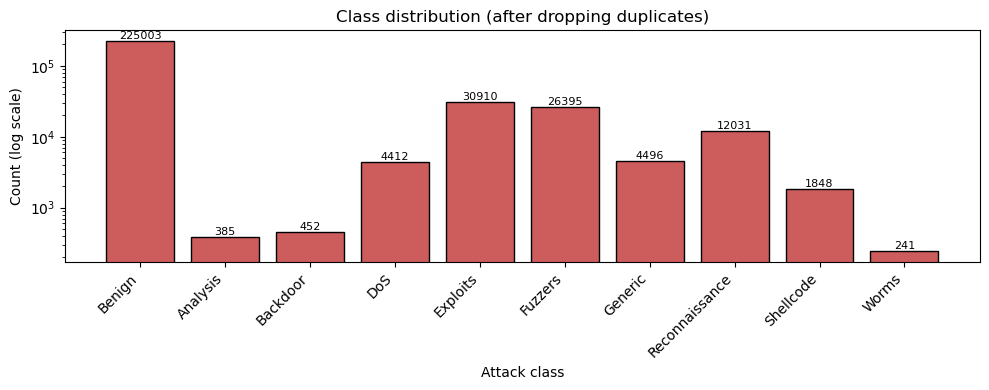

In [5]:
# Official label mapping (not stored in the CSVs). Attack families are alphabetical, Benign = 0.
LABELS = {
    0: "Benign", 1: "Analysis", 2: "Backdoor", 3: "DoS", 4: "Exploits",
    5: "Fuzzers", 6: "Generic", 7: "Reconnaissance", 8: "Shellcode", 9: "Worms",
}

counts = y["Label"].value_counts().sort_index()
dist = pd.DataFrame({
    "attack": [LABELS[i] for i in counts.index],
    "count": counts.values,
    "percent": (counts.values / counts.sum() * 100).round(3),
}, index=counts.index)
dist.index.name = "label"
print(dist)

plt.figure(figsize=(10, 4))
bars = plt.bar([LABELS[i] for i in counts.index], counts.values,
               color="indianred", edgecolor="black")
plt.yscale("log")
plt.title("Class distribution (after dropping duplicates)")
plt.xlabel("Attack class"); plt.ylabel("Count (log scale)")
plt.xticks(rotation=45, ha="right")
plt.bar_label(bars, fontsize=8)
plt.tight_layout(); plt.show()

### 2.4 Variance check

A feature with only one unique value (zero variance) carries no information.

In [6]:
nunique = X.nunique()
zero_var_cols = nunique[nunique <= 1].index.tolist()

print(f"Total features:           {X.shape[1]}")
print(f"Zero-variance (constant): {len(zero_var_cols)}\n")
for c in zero_var_cols:
    print(f"  {c:<22} -> constant value = {X[c].iloc[0]}")

Total features:           76
Zero-variance (constant): 9

  Bwd PSH Flags          -> constant value = 0
  Fwd URG Flags          -> constant value = 0
  Bwd URG Flags          -> constant value = 0
  URG Flag Count         -> constant value = 0
  CWR Flag Count         -> constant value = 0
  ECE Flag Count         -> constant value = 0
  Fwd Bytes/Bulk Avg     -> constant value = 0
  Fwd Packet/Bulk Avg    -> constant value = 0
  Fwd Bulk Rate Avg      -> constant value = 0


### 2.5 Correlation

Highly correlated features add redundancy without new signal. Constant columns from 2.4 are excluded.

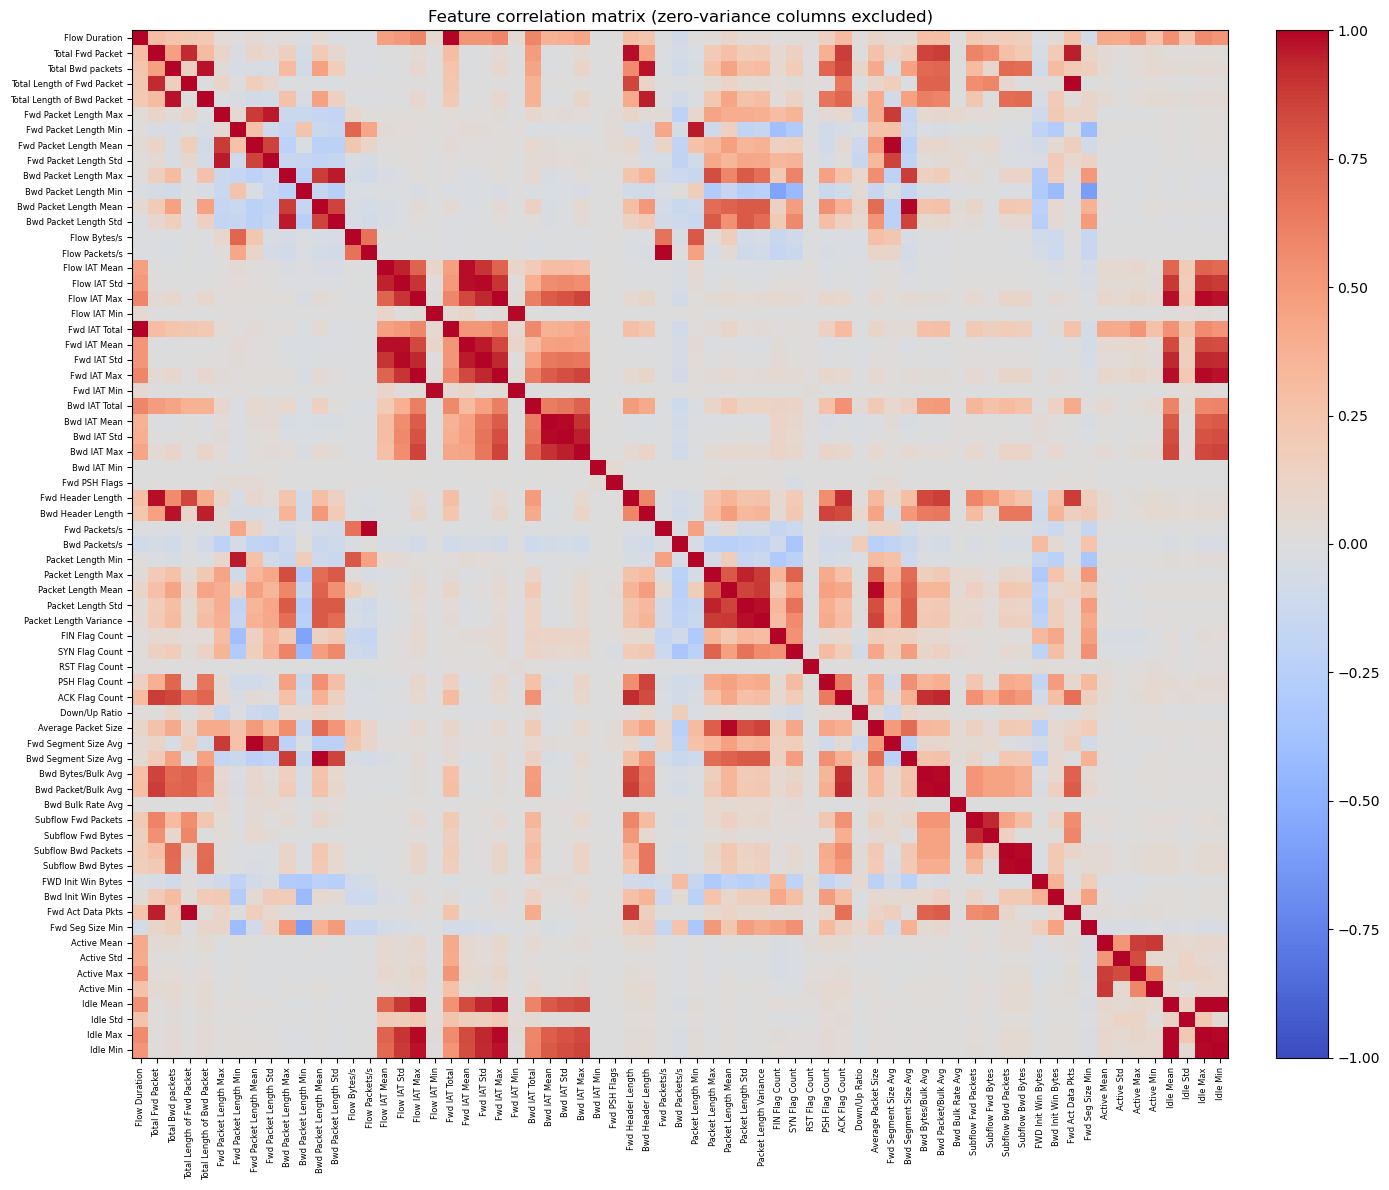

In [7]:
features = X.drop(columns=zero_var_cols)
corr = features.corr()

plt.figure(figsize=(14, 12))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
plt.yticks(range(len(corr)), corr.columns, fontsize=6)
plt.title("Feature correlation matrix (zero-variance columns excluded)")
plt.tight_layout(); plt.show()

In [8]:
# List highly correlated feature pairs (upper triangle only).
THRESHOLD = 0.95

upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = (upper.stack().reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_corr"}))
high_pairs = high_pairs[high_pairs["abs_corr"] >= THRESHOLD].sort_values(
    "abs_corr", ascending=False).reset_index(drop=True)

print(f"Highly correlated pairs (|r| >= {THRESHOLD}): {len(high_pairs)}\n")
print(high_pairs.to_string(index=False))

Highly correlated pairs (|r| >= 0.95): 31

                 feature_1                  feature_2  abs_corr
    Fwd Packet Length Mean       Fwd Segment Size Avg  1.000000
    Bwd Packet Length Mean       Bwd Segment Size Avg  1.000000
            Flow Packets/s              Fwd Packets/s  0.999304
             Flow Duration              Fwd IAT Total  0.999037
              Flow IAT Max                Fwd IAT Max  0.997462
                 Idle Mean                   Idle Min  0.997389
                 Idle Mean                   Idle Max  0.995172
Total Length of Fwd Packet          Fwd Act Data Pkts  0.993241
        Packet Length Mean        Average Packet Size  0.991194
              Flow IAT Std                Fwd IAT Std  0.988993
        Bwd Bytes/Bulk Avg        Bwd Packet/Bulk Avg  0.988857
              Flow IAT Max                   Idle Max  0.988439
       Subflow Bwd Packets          Subflow Bwd Bytes  0.988309
                  Idle Max                   Idle Min  0.9863

### 2.6 Drop uninformative & redundant features

Drop zero-variance columns (2.4) and, for each highly-correlated pair (2.5), keep the first and drop the later.

In [9]:
redundant_cols = [c for c in upper.columns if (upper[c] >= THRESHOLD).any()]
drop_cols = list(dict.fromkeys(zero_var_cols + redundant_cols))

print(f"Zero-variance to drop ({len(zero_var_cols)}):\n ", zero_var_cols, "\n")
print(f"Redundant |r|>={THRESHOLD} to drop ({len(redundant_cols)}):\n ", redundant_cols, "\n")
print(f"Total unique columns to drop: {len(drop_cols)}")

X = X.drop(columns=drop_cols)
print(f"\nFeatures remaining: {X.shape[1]} (from 76)")

Zero-variance to drop (9):
  ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Count', 'CWR Flag Count', 'ECE Flag Count', 'Fwd Bytes/Bulk Avg', 'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg'] 

Redundant |r|>=0.95 to drop (23):
  ['Total Length of Bwd Packet', 'Fwd Packet Length Std', 'Bwd Packet Length Std', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Std', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Packet Length Min', 'Packet Length Variance', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg', 'Bwd Packet/Bulk Avg', 'Subflow Bwd Bytes', 'Fwd Act Data Pkts', 'Idle Mean', 'Idle Max', 'Idle Min'] 

Total unique columns to drop: 32

Features remaining: 44 (from 76)


### 2.7 Stratified train/test split

Split **before** anything downstream so nothing leaks. `stratify=y` preserves each class's proportion.
Gradient-boosted trees are scale-invariant, so no scaling. Labels are already `0-9`.

In [10]:
from sklearn.model_selection import train_test_split

y_series = y["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_series, test_size=0.2, random_state=42, stratify=y_series,
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (244938, 44) | Test: (61235, 44)


### 2.8 Derive the two-stage label views

Both views come from the **same split** (no second split -> no leakage, fully comparable to the baselines).
- **Gate (Stage A):** binary, `0 = Benign`, `1 = Attack`.
- **Family (Stage B):** attack rows only. XGBoost needs labels `0..k-1`, so remap families `1-9 -> 0-8`
  and keep the inverse map for decoding.

In [11]:
# Stage A: binary gate
y_train_bin = (y_train != 0).astype(int)
y_test_bin  = (y_test  != 0).astype(int)

# Stage B: family classifier, ATTACK ROWS ONLY (remap 1-9 -> 0-8)
attack_labels = sorted(l for l in y_train.unique() if l != 0)   # [1..9]
fam_to_idx = {fam: i for i, fam in enumerate(attack_labels)}
idx_to_fam = {i: fam for fam, i in fam_to_idx.items()}

train_att   = y_train != 0
X_train_att = X_train[train_att]
y_train_att = y_train[train_att].map(fam_to_idx)               # 0..8

print("Stage A (gate) train balance:")
print(y_train_bin.value_counts().rename({0: "Benign", 1: "Attack"}))
print(f"\nStage B (family) trains on attack rows only: {X_train_att.shape[0]} rows, "
      f"{len(attack_labels)} classes")

Stage A (gate) train balance:
Label
Benign    180002
Attack     64936
Name: count, dtype: int64

Stage B (family) trains on attack rows only: 64936 rows, 9 classes


## 3. Model Selection
_Algorithm Choice_

Both stages use **XGBoost** (the strongest single baseline, macro-F1 0.5807). Keeping the same learner
isolates the gain from the **hierarchy**, not from swapping algorithms. We let the sklearn wrapper infer
the objective from each stage's labels (binary logistic for the gate, multiclass softprob for the 9-class
family) - passing `num_class` manually to the wrapper conflicts with its own class inference.

In [12]:
from xgboost import XGBClassifier

def make_xgb():
    return XGBClassifier(
        n_estimators=400, max_depth=8, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9,
        tree_method="hist", eval_metric="mlogloss",
        n_jobs=-1, random_state=42,
    )

stage_a = make_xgb()   # gate:   Benign vs Attack (binary, inferred)
stage_b = make_xgb()   # family: 9 attack classes (multiclass, inferred)
print("Stage A: gate (2 classes) | Stage B: family (", len(attack_labels), "classes)")

Stage A: gate (2 classes) | Stage B: family ( 9 classes)


## 4. Model Training
_Learning Process_

Each stage is fit on the training split only, with `balanced` per-sample weights (the imbalance lever used
across all baselines). The gate is still Benign-heavy; the family stage is imbalanced among attacks - both
get balanced weights.

In [13]:
from sklearn.utils.class_weight import compute_sample_weight

# Stage A - gate
sw_a = compute_sample_weight(class_weight="balanced", y=y_train_bin)
stage_a.fit(X_train, y_train_bin, sample_weight=sw_a)

# Stage B - family (attack rows only)
sw_b = compute_sample_weight(class_weight="balanced", y=y_train_att)
stage_b.fit(X_train_att, y_train_att, sample_weight=sw_b)

print("Both stages trained.")

Both stages trained.


## 5. Model Evaluation
_Test Performance_

Evaluated on the **same** `X_test` / `y_test` as the baselines, so **macro-F1** is directly comparable.

**Inference:** hard gate - predict Benign unless the gate says Attack, then take Stage B's family.
For ROC-AUC we compose calibrated 10-class probabilities:
`P(Benign)=P_gate(Benign)`, `P(family f)=P_gate(Attack) x P_familyB(f)` (rows sum to 1).

### 5.1 Metrics

In [14]:
# --- Hierarchical inference on the test set ---
gate_pred = stage_a.predict(X_test)                 # 0=Benign, 1=Attack
y_pred = np.zeros(len(X_test), dtype=int)           # default Benign (0)
att_mask = gate_pred == 1
if att_mask.any():
    fam_idx = stage_b.predict(X_test[att_mask])
    y_pred[att_mask] = np.vectorize(idx_to_fam.get)(fam_idx)

# Composed 10-class probabilities for ROC-AUC
pA = stage_a.predict_proba(X_test)                  # [:,0]=Benign, [:,1]=Attack
pB = stage_b.predict_proba(X_test)                  # columns in idx (0..8) order
y_proba = np.zeros((len(X_test), 10))
y_proba[:, 0] = pA[:, 0]
for i, fam in idx_to_fam.items():
    y_proba[:, fam] = pA[:, 1] * pB[:, i]

In [15]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

labels_sorted = list(range(10))
target_names = [LABELS[i] for i in labels_sorted]

roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
print(f"Accuracy    : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}   (macro, One-vs-Rest, composed probabilities)\n")

print(f"{'':<12}{'weighted':>10}{'macro':>10}")
for name, metric in [("Precision", precision_score), ("Recall", recall_score), ("F1-score", f1_score)]:
    w = metric(y_test, y_pred, average="weighted", zero_division=0)
    m = metric(y_test, y_pred, average="macro", zero_division=0)
    note = "   <- macro F1 = primary metric" if name == "F1-score" else ""
    print(f"{name:<12}{w:>10.4f}{m:>10.4f}{note}")

print()
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

Accuracy    : 0.8944
ROC-AUC     : 0.9812   (macro, One-vs-Rest, composed probabilities)

              weighted     macro
Precision       0.9162    0.5427
Recall          0.8944    0.6779
F1-score        0.9020    0.5858   <- macro F1 = primary metric

                precision    recall  f1-score   support

        Benign     0.9987    0.9677    0.9829     45001
      Analysis     0.3295    0.7532    0.4585        77
      Backdoor     0.4860    0.5778    0.5279        90
           DoS     0.3906    0.4428    0.4151       883
      Exploits     0.8775    0.6661    0.7573      6182
       Fuzzers     0.6448    0.7475    0.6923      5279
       Generic     0.7042    0.8287    0.7614       899
Reconnaissance     0.4974    0.7028    0.5825      2406
     Shellcode     0.1984    0.5297    0.2887       370
         Worms     0.3000    0.5625    0.3913        48

      accuracy                         0.8944     61235
     macro avg     0.5427    0.6779    0.5858     61235
  weighted avg  

### 5.2 Stage diagnostics

Where does the error come from - the gate or the family stage? Report the gate's binary performance and
the family stage's macro-F1 on the *true* attack rows (its own subproblem, an upper bound for the pipeline).

In [16]:
# Gate (binary) on the full test set
print("Stage A - Gate (Benign vs Attack):")
print(classification_report(y_test_bin, gate_pred, target_names=["Benign", "Attack"], digits=4))

# Family stage in isolation: true attack rows only
test_att     = y_test != 0
famB_on_true = stage_b.predict(X_test[test_att])
y_true_fam   = y_test[test_att].map(fam_to_idx)
print("Stage B - Family (on TRUE attack rows only):")
print(f"  macro-F1 = {f1_score(y_true_fam, famB_on_true, average='macro', zero_division=0):.4f} "
      f"over {len(attack_labels)} attack families")
print(f"  accuracy = {accuracy_score(y_true_fam, famB_on_true):.4f}")

Stage A - Gate (Benign vs Attack):
              precision    recall  f1-score   support

      Benign     0.9987    0.9677    0.9829     45001
      Attack     0.9175    0.9966    0.9554     16234

    accuracy                         0.9753     61235
   macro avg     0.9581    0.9821    0.9692     61235
weighted avg     0.9772    0.9753    0.9756     61235

Stage B - Family (on TRUE attack rows only):
  macro-F1 = 0.5742 over 9 attack families
  accuracy = 0.6930


### 5.3 Confusion matrix

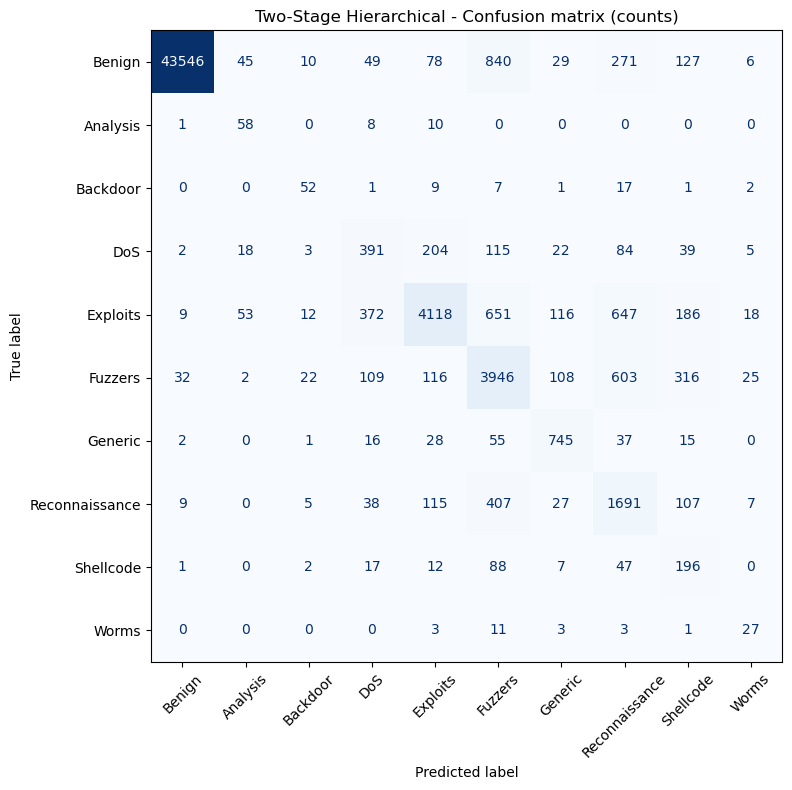

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Two-Stage Hierarchical - Confusion matrix (counts)")
plt.tight_layout(); plt.show()

## 6. Model Improvement
_Fine-tune & Optimize_

The gate's decision threshold is a free lever: **lowering** it lets more traffic through to Stage B
(higher attack recall, more false alarms), **raising** it does the opposite. Sweep the threshold on the
gate's Attack-probability and pick by **macro-F1 of the full 10-class output**.

> Shown here on the test set for illustration. For a reported result, tune the threshold on a
> validation split carved from the *training* data, then evaluate once on test.

In [18]:
thresholds = np.linspace(0.1, 0.9, 17)
rows = []
for t in thresholds:
    gp = (pA[:, 1] >= t).astype(int)
    yp = np.zeros(len(X_test), dtype=int)
    m = gp == 1
    if m.any():
        yp[m] = np.vectorize(idx_to_fam.get)(stage_b.predict(X_test[m]))
    rows.append((round(float(t), 3),
                 f1_score(y_test, yp, average="macro", zero_division=0),
                 recall_score(y_test_bin, gp, zero_division=0),
                 precision_score(y_test_bin, gp, zero_division=0)))

sweep = pd.DataFrame(rows, columns=["gate_thr", "macro_F1", "attack_recall", "attack_precision"])
best = sweep.loc[sweep["macro_F1"].idxmax()]
default_f1 = sweep.loc[sweep.gate_thr == 0.5, "macro_F1"].iloc[0]
print(sweep.to_string(index=False))
print(f"\nBest gate threshold by macro-F1: {best.gate_thr:.2f} -> macro-F1 {best.macro_F1:.4f} "
      f"(default 0.50 = {default_f1:.4f})")

 gate_thr  macro_F1  attack_recall  attack_precision
     0.10  0.583734       0.999877          0.905753
     0.15  0.584075       0.999569          0.907804
     0.20  0.584780       0.999322          0.910331
     0.25  0.584979       0.999014          0.911533
     0.30  0.585235       0.998460          0.912926
     0.35  0.585486       0.998398          0.914054
     0.40  0.586012       0.997844          0.915043
     0.45  0.586193       0.997351          0.916143
     0.50  0.585795       0.996550          0.917484
     0.55  0.585768       0.994764          0.919856
     0.60  0.585321       0.993347          0.921275
     0.65  0.585718       0.990760          0.924049
     0.70  0.586406       0.987064          0.927798
     0.75  0.586508       0.982444          0.931437
     0.80  0.585271       0.975976          0.934860
     0.85  0.586333       0.964396          0.938778
     0.90  0.582788       0.938524          0.946042

Best gate threshold by macro-F1: 0.75 -> macr

## 7. Prediction
_Deployment & Inference_

`predict_flows` runs the full hierarchy on new, already-preprocessed flows (same feature columns as
`X_train`) and returns class names. `gate_threshold` exposes the Stage-6 lever at inference time.

In [19]:
def predict_flows(X_new, gate_threshold=0.5):
    pA_new = stage_a.predict_proba(X_new)
    gate = (pA_new[:, 1] >= gate_threshold).astype(int)
    out = np.zeros(len(X_new), dtype=int)
    m = gate == 1
    if m.any():
        out[m] = np.vectorize(idx_to_fam.get)(stage_b.predict(X_new[m]))
    return np.array([LABELS[i] for i in out])

# Smoke test on the first 5 test flows
sample_pred = predict_flows(X_test.iloc[:5])
print("Predicted:", list(sample_pred))
print("Actual   :", [LABELS[i] for i in y_test.iloc[:5]])

Predicted: ['Benign', 'Benign', 'Benign', 'Benign', 'Reconnaissance']
Actual   : ['Benign', 'Benign', 'Benign', 'Benign', 'Reconnaissance']
